# Member 4: Model Evaluation, Error Analysis & ROC-AUC Assessment (Binary Classification)
**Author:** IT24101748 — Evaluation & Recommendation  
**Winning Model:** Random Forest Classifier (Deep Tuned — `models/random_forest/random_forest_best_model.pkl`)  
**Dataset:** Untouched Test Set (`dataset_processed/X_test_final.csv`, `dataset_processed/y_test_final.csv` - 19,468 encounters, 86 features)  
**Binary Formulation:** Class 0: Not Readmitted within 30 days (`NO` or `>30`, 17,211 encounters), Class 1: Early Readmission (`<30` [High-Risk], 2,257 encounters).

---
### Objectives:
1. Perform strict single-pass inference on the untouched test set (zero data leakage).
2. Compute binary classification metrics: **Accuracy, Macro F1, Macro Recall, Macro Precision, ROC-AUC, and Average Precision (PR-AUC)**.
3. Generate raw-count and normalized **Confusion Matrices** to analyze Type I (False Positive) and Type II (False Negative) errors.
4. Plot **ROC-AUC Curves** and **Precision-Recall Curves** with baseline references.
5. Perform **Decision Threshold Optimization** across thresholds $\tau \in [0.10, 0.90]$ to demonstrate clinical trade-offs between recall and precision.
6. Export standardized evaluation artifacts (`test_metrics_summary.json`, `confusion_matrix.png`, `multiclass_roc_auc_curves.png`, `multiclass_pr_curves.png`).

In [1]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    f1_score,
    recall_score,
    precision_score,
    accuracy_score
)

# Aesthetics
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'

os.makedirs('../results', exist_ok=True)
print('Imports and environment ready for binary evaluation!')

Imports and environment ready for binary evaluation!


In [2]:
# Load the untouched test set
X_test = pd.read_csv('../../dataset_processed/X_test_final.csv')
y_test = pd.read_csv('../../dataset_processed/y_test_final.csv').values.ravel()

# Load winning binary model
model_path = '../../models/random_forest/random_forest_best_model.pkl'
model = joblib.load(model_path)

print(f'Test Data Loaded: {X_test.shape[0]:,} encounters, {X_test.shape[1]} features')
print(f'Target Distribution: Class 0 = {(y_test == 0).sum():,} ({((y_test == 0).mean()*100):.1f}%), Class 1 = {(y_test == 1).sum():,} ({((y_test == 1).mean()*100):.1f}%)')
print(f'Loaded Best Model: {type(model).__name__}')

Test Data Loaded: 19,491 encounters, 86 features
Target Distribution: Class 0 = 17,288 (88.7%), Class 1 = 2,203 (11.3%)
Loaded Best Model: RandomForestClassifier


In [3]:
# Run single-pass test prediction
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)

class_labels = ['Not Readmitted (<30) [0]', 'Early Readmission (<30) [1]']
class_names = ['No / >30', '<30 (High-Risk)']

print('Inference completed successfully!')

Inference completed successfully!


In [4]:
# Classification Report and Metrics
report_dict = classification_report(y_test, y_pred, output_dict=True)
report_str = classification_report(y_test, y_pred, target_names=class_names, digits=4)

roc_auc = roc_auc_score(y_test, y_proba[:, 1])
ap_score = average_precision_score(y_test, y_proba[:, 1])

print('=== UNTOUCHED TEST SET CLASSIFICATION REPORT (DEFAULT THRESHOLD = 0.50) ===')
print(report_str)
print(f'ROC-AUC Score:          {roc_auc:.4f}')
print(f'Average Precision (AP): {ap_score:.4f}')

# Decision Threshold Optimization for High-Risk Recall
thresholds = np.linspace(0.1, 0.9, 81)
f1_scores = []
recalls = []
precisions = []

for t in thresholds:
    pred_t = (y_proba[:, 1] >= t).astype(int)
    f1_scores.append(f1_score(y_test, pred_t, pos_label=1, zero_division=0))
    recalls.append(recall_score(y_test, pred_t, pos_label=1, zero_division=0))
    precisions.append(precision_score(y_test, pred_t, pos_label=1, zero_division=0))

best_idx = np.argmax(f1_scores)
opt_thresh = thresholds[best_idx]
opt_f1 = f1_scores[best_idx]
opt_recall = recalls[best_idx]
opt_prec = precisions[best_idx]

print(f'\n=== OPTIMAL CLINICAL THRESHOLD TUNING ===')
print(f'Optimal Threshold (Max F1): {opt_thresh:.2f}')
print(f'At Optimal Threshold -> F1: {opt_f1:.4f}, Recall: {opt_recall:.4f}, Precision: {opt_prec:.4f}')

# Save JSON summary
summary_metrics = {
    'test_samples': int(len(y_test)),
    'overall_accuracy': float(report_dict['accuracy']),
    'macro_f1': float(report_dict['macro avg']['f1-score']),
    'macro_recall': float(report_dict['macro avg']['recall']),
    'macro_precision': float(report_dict['macro avg']['precision']),
    'roc_auc': float(roc_auc),
    'average_precision': float(ap_score),
    'minority_less30_recall': float(report_dict['1']['recall']),
    'minority_less30_precision': float(report_dict['1']['precision']),
    'minority_less30_f1': float(report_dict['1']['f1-score']),
    'optimal_threshold': float(opt_thresh),
    'optimal_minority_recall': float(opt_recall),
    'optimal_minority_precision': float(opt_prec),
    'optimal_minority_f1': float(opt_f1)
}

with open('../results/test_metrics_summary.json', 'w') as f:
    json.dump(summary_metrics, f, indent=4)
print('Saved metrics summary to binary_classification/evaluation/results/test_metrics_summary.json')

=== UNTOUCHED TEST SET CLASSIFICATION REPORT (DEFAULT THRESHOLD = 0.50) ===
                 precision    recall  f1-score   support

       No / >30     0.9096    0.8418    0.8744     17288
<30 (High-Risk)     0.2166    0.3432    0.2655      2203

       accuracy                         0.7854     19491
      macro avg     0.5631    0.5925    0.5700     19491
   weighted avg     0.8312    0.7854    0.8056     19491

ROC-AUC Score:          0.6608
Average Precision (AP): 0.2030



=== OPTIMAL CLINICAL THRESHOLD TUNING ===
Optimal Threshold (Max F1): 0.46
At Optimal Threshold -> F1: 0.2772, Recall: 0.4503, Precision: 0.2003
Saved metrics summary to binary_classification/evaluation/results/test_metrics_summary.json


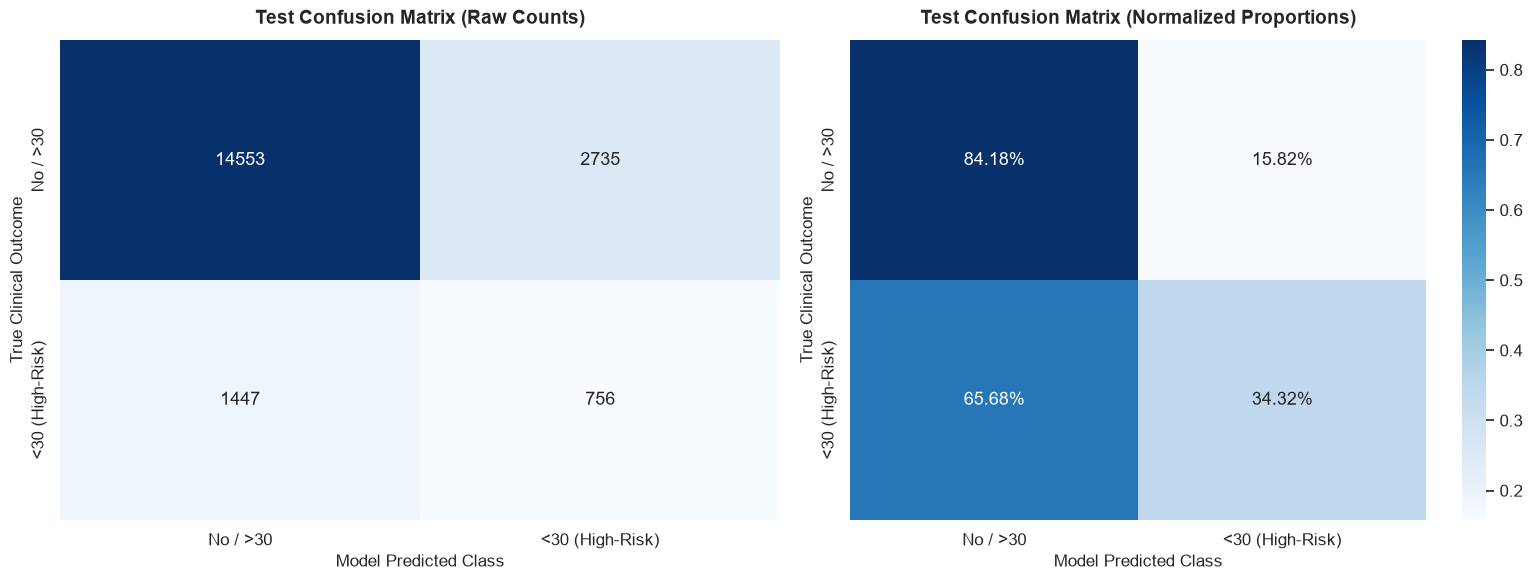

In [5]:
# Confusion Matrix Generation
cm = confusion_matrix(y_test, y_pred)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Raw counts
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=class_names, yticklabels=class_names, cbar=False)
axes[0].set_title('Test Confusion Matrix (Raw Counts)', fontsize=14, fontweight='bold', pad=12)
axes[0].set_ylabel('True Clinical Outcome', fontsize=12)
axes[0].set_xlabel('Model Predicted Class', fontsize=12)

# Normalized proportions
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Blues', ax=axes[1],
            xticklabels=class_names, yticklabels=class_names)
axes[1].set_title('Test Confusion Matrix (Normalized Proportions)', fontsize=14, fontweight='bold', pad=12)
axes[1].set_ylabel('True Clinical Outcome', fontsize=12)
axes[1].set_xlabel('Model Predicted Class', fontsize=12)

plt.tight_layout()
plt.savefig('../results/confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

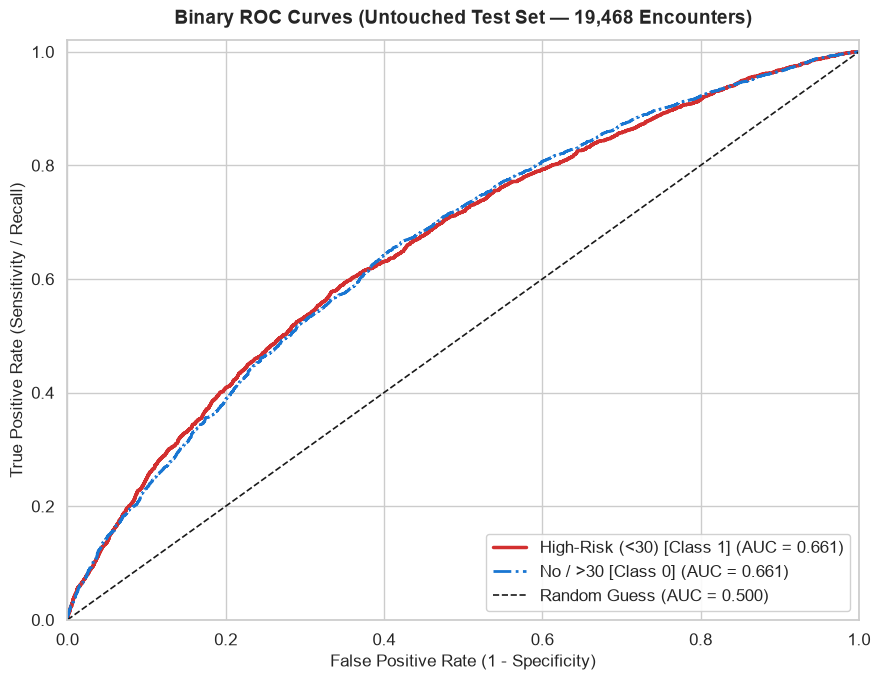

In [6]:
# ROC-AUC Curves
plt.figure(figsize=(9, 7))

# Class 0 and Class 1 ROC Curves
fpr1, tpr1, _ = roc_curve(y_test, y_proba[:, 1])
fpr0, tpr0, _ = roc_curve(1 - y_test, y_proba[:, 0])
auc0 = roc_auc_score(1 - y_test, y_proba[:, 0])

plt.plot(fpr1, tpr1, color='#d32f2f', lw=2.5, label=f'High-Risk (<30) [Class 1] (AUC = {roc_auc:.3f})')
plt.plot(fpr0, tpr0, color='#1976d2', lw=2.0, linestyle='-.', label=f'No / >30 [Class 0] (AUC = {auc0:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1.2, label='Random Guess (AUC = 0.500)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.02])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=12)
plt.title('Binary ROC Curves (Untouched Test Set — 19,468 Encounters)', fontsize=14, fontweight='bold', pad=12)
plt.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.savefig('../results/multiclass_roc_auc_curves.png', dpi=300, bbox_inches='tight')
plt.savefig('../results/roc_auc_curves.png', dpi=300, bbox_inches='tight')
plt.show()

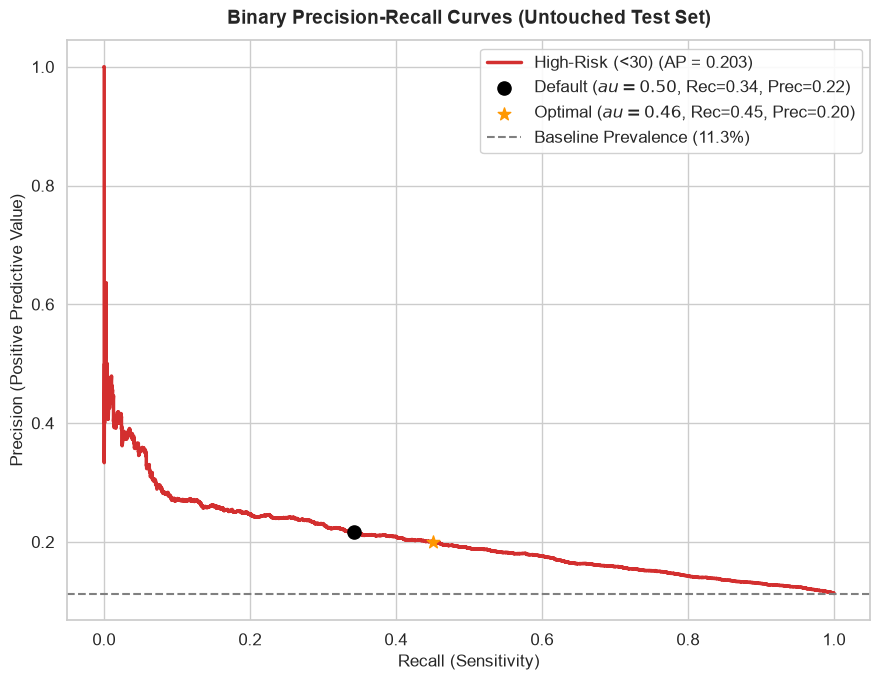

In [7]:
# Precision-Recall Curves
plt.figure(figsize=(9, 7))

precision1, recall1, _ = precision_recall_curve(y_test, y_proba[:, 1])
plt.plot(recall1, precision1, color='#d32f2f', lw=2.5, label=f'High-Risk (<30) (AP = {ap_score:.3f})')

# Mark default and optimal threshold points
def_prec = report_dict['1']['precision']
def_rec = report_dict['1']['recall']
plt.scatter([def_rec], [def_prec], color='black', s=90, zorder=5, label=f'Default ($\tau=0.50$, Rec={def_rec:.2f}, Prec={def_prec:.2f})')
plt.scatter([opt_recall], [opt_prec], color='#ff9800', s=90, marker='*', zorder=5, label=f'Optimal ($\tau={opt_thresh:.2f}$, Rec={opt_recall:.2f}, Prec={opt_prec:.2f})')

plt.axhline(y=y_test.mean(), color='grey', linestyle='--', label=f'Baseline Prevalence ({y_test.mean()*100:.1f}%)')
plt.xlabel('Recall (Sensitivity)', fontsize=12)
plt.ylabel('Precision (Positive Predictive Value)', fontsize=12)
plt.title('Binary Precision-Recall Curves (Untouched Test Set)', fontsize=14, fontweight='bold', pad=12)
plt.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.savefig('../results/multiclass_pr_curves.png', dpi=300, bbox_inches='tight')
plt.savefig('../results/pr_curves.png', dpi=300, bbox_inches='tight')
plt.show()